# Phase II: Supervised Transformer Classification & Hybrid Early Fusion Meta-Learner
### Manuscript Title: *Early Fusion of Dual-Transformer Embeddings with an XGBoost Meta-Learner for Automated Resume Classification*
### IEEE Access | Manuscript Tracking: **Access-2026-45264**
---
## Overview of Phase II Experimental Pipeline
Phase II evaluates supervised contextual representation learning and dual-transformer early fusion across the held-out test partition (=376$ resumes across 17 professional categories).
This notebook implements:
1. **Model 1: MPNet Semantic Matching Baseline** (dense semantic centroid retrieval).
2. **Model 2: DistilBERT Supervised Classification Baseline** (fine-tuned localized contextual representations).
3. **Model 3: Traditional Supervised XGBoost Baseline** (trained on 5000-D sparse TF-IDF n-grams).
4. **Model 4: Proposed Hybrid Early Fusion Architecture** (horizontal concatenation of 768-D DistilBERT [CLS] and 768-D MPNet embeddings into a 1536-D space, classified via an XGBoost meta-learner).
5. **Comparative Diagnostic Suite:** Generating publication-quality charts for overall performance (**Figure 10**), per-class F1 comparisons (**Figure 11**), prediction confidence calibration (**Figure 13**), and feature importance.


In [1]:
import pandas as pd
import numpy as np
import torch
import xgboost as xgb
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from sentence_transformers import SentenceTransformer
from datasets import Dataset
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import os

print("CUDA Available:", torch.cuda.is_available())
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


CUDA Available: True


In [2]:
# =========================================
# 1. LOAD CLEAN DATASETS & PREPARE SPLITS
# =========================================
job_df = pd.read_csv(
    "hf://datasets/azrai99/job-dataset/jobstreet_all_job_dataset.csv"
)

resume_df = pd.read_csv(
    "hf://datasets/opensporks/resumes/Resume/Resume.csv"
)
resume_df["Category"] = (
    resume_df["Category"]
    .str.strip()
    .str.upper()
)
category_mapping = {
    "Human Resources & Recruitment": "HR",
    "Accounting": "ACCOUNTANT",
    "Engineering": "ENGINEERING",
    "Information & Communication Technology": "INFORMATION-TECHNOLOGY",
    "Sales": "SALES",
    "Retail & Consumer Products": "SALES",
    "Banking & Financial Services": "BANKING",
    "Insurance & Superannuation": "FINANCE",
    "Construction": "CONSTRUCTION",
    "Consulting & Strategy": "CONSULTANT",
    "CEO & General Management": "BUSINESS-DEVELOPMENT",
    "Design & Architecture": "DESIGNER",
    "Advertising, Arts & Media": "DIGITAL-MEDIA",
    "Education & Training": "TEACHER",
    "Healthcare & Medical": "HEALTHCARE",
    "Legal": "ADVOCATE",
    "Farming, Animals & Conservation": "AGRICULTURE",
    "Sport & Recreation": "FITNESS"
}
job_df["Mapped_Category"] = job_df["category"].map(category_mapping)

# Remove categories that don't have a mapping
job_df = job_df.dropna(subset=["Mapped_Category"]).copy()

# Keep only required columns
job_df_clean = job_df[
    ["job_title", "descriptions", "Mapped_Category"]
]

# =========================================
# 5. FILTER RESUMES TO MATCH CATEGORIES
# =========================================

valid_categories = list(set(category_mapping.values()))

resume_df_clean = resume_df[
    resume_df["Category"].isin(valid_categories)
].copy()

# =========================================
# 6. SAVE CLEAN DATASETS
# =========================================

resume_df_clean.to_csv(
    "clean_resumes.csv",
    index=False
)

job_df_clean.to_csv(
    "clean_job_descriptions.csv",
    index=False
)

# =========================================
# 4. MAP JOB CATEGORIES
# =========================================

job_df["Mapped_Category"] = job_df["category"].map(category_mapping)

# Remove categories that don't have a mapping
job_df = job_df.dropna(subset=["Mapped_Category"]).copy()
resume_df = pd.read_csv("clean_resumes.csv")
resume_df.columns = resume_df.columns.str.lower()
job_df = pd.read_csv("clean_job_descriptions.csv")
job_df.columns = job_df.columns.str.lower()

label_encoder = LabelEncoder()
resume_df['label'] = label_encoder.fit_transform(resume_df['category'])

train_df, test_df = train_test_split(
    resume_df,
    test_size=0.2,
    stratify=resume_df["category"],
    random_state=42
)

train_texts = train_df["resume_str"].tolist()
train_labels = train_df["label"].values
test_texts = test_df["resume_str"].tolist()
test_labels = test_df["label"].values
num_labels = len(label_encoder.classes_)
unique_categories = label_encoder.classes_

print(f"Train size: {len(train_texts)}, Test size: {len(test_texts)}")

# Dictionary to store metrics for comparison
model_metrics = {}
# Dictionary to store predictions for analysis
model_preds = {}
# Dictionary to store probabilities
model_probs = {}


Train size: 1504, Test size: 376


In [3]:
def plot_confusion_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=unique_categories, yticklabels=unique_categories)
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

def evaluate_model(model_name, y_true, y_pred, y_probs):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='macro', zero_division=0)
    rec = recall_score(y_true, y_pred, average='macro', zero_division=0)
    f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
    
    print(f"\n=== {model_name} RESULTS ===")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"Macro F1:  {f1:.4f}")
    
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=unique_categories, zero_division=0))
    
    plot_confusion_matrix(y_true, y_pred, f"{model_name} - Confusion Matrix")
    
    model_metrics[model_name] = {'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'Macro F1': f1}
    model_preds[model_name] = y_pred
    model_probs[model_name] = y_probs


## Model 1: MPNet (Semantic Matching)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

... (10 outputs left out)

Batches:   0%|          | 0/47 [00:00<?, ?it/s]


Extracting MPNet features for Test set...
Encoding resumes...


Batches:   0%|          | 0/12 [00:00<?, ?it/s]


=== MPNet Semantic Matching RESULTS ===
Accuracy:  0.5878
Precision: 0.6162
Recall:    0.5876
Macro F1:  0.5466

Classification Report:
                        precision    recall  f1-score   support

            ACCOUNTANT       0.59      1.00      0.74        24
              ADVOCATE       1.00      0.04      0.08        24
           AGRICULTURE       0.67      0.31      0.42        13
               BANKING       0.54      0.61      0.57        23
  BUSINESS-DEVELOPMENT       0.00      0.00      0.00        24
          CONSTRUCTION       0.91      0.45      0.61        22
            CONSULTANT       0.33      0.30      0.32        23
              DESIGNER       1.00      0.71      0.83        21
         DIGITAL-MEDIA       0.86      0.63      0.73        19
           ENGINEERING       0.62      0.83      0.71        24
               FINANCE       0.09      0.04      0.06        24
               FITNESS       1.00      0.61      0.76        23
            HEALTHCARE       0

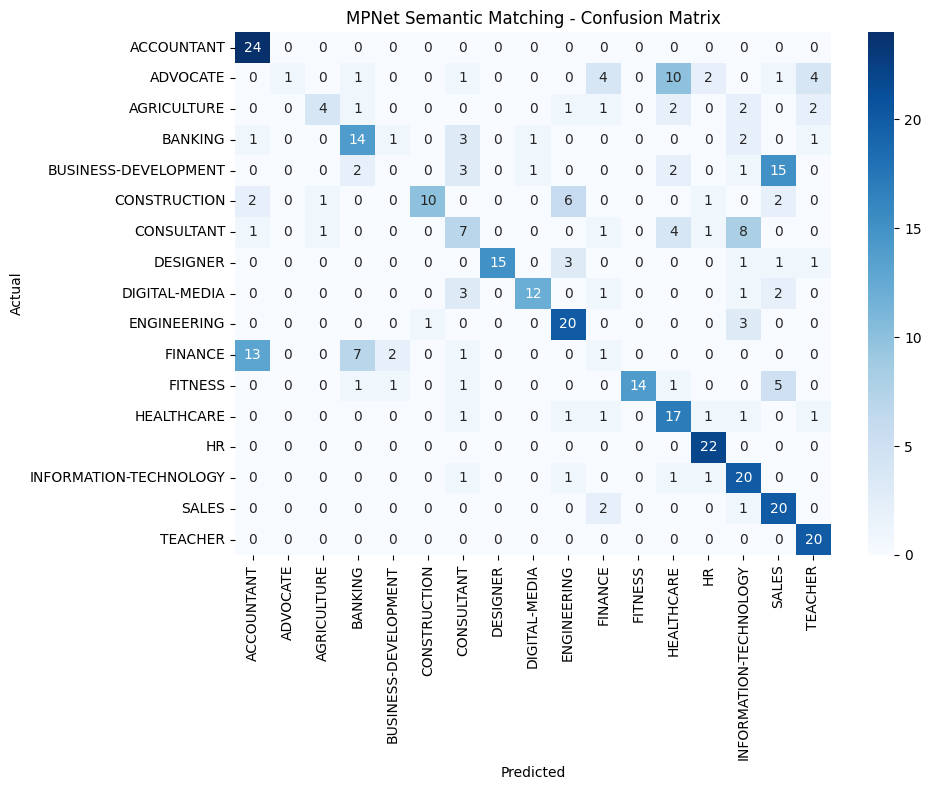

In [4]:
mpnet_model = SentenceTransformer("all-mpnet-base-v2", device=device)

# Compute Job Centroids
job_categories = job_df["mapped_category"].values

print("Encoding Job Descriptions with MPNet...")
job_texts = job_df["descriptions"].tolist()
job_embeddings = mpnet_model.encode(job_texts, batch_size=32, show_progress_bar=True)

centroid_embeddings = []
for cat in unique_categories:
    idx = np.where(job_categories == cat)[0]
    if len(idx) > 0:
        centroid = np.mean(job_embeddings[idx], axis=0)
        centroid_embeddings.append(centroid)
    else:
        centroid_embeddings.append(np.zeros(768))
centroid_embeddings = np.vstack(centroid_embeddings)

def extract_mpnet_features(texts):
    print("Encoding resumes...")
    embs = mpnet_model.encode(texts, batch_size=32, show_progress_bar=True)
    embs_norm = embs / np.linalg.norm(embs, axis=1, keepdims=True)
    cents_norm = centroid_embeddings / np.linalg.norm(centroid_embeddings, axis=1, keepdims=True)
    sim_scores = np.dot(embs_norm, cents_norm.T)
    probs = F.softmax(torch.tensor(sim_scores) * 10, dim=-1).numpy()
    return embs, probs

print("\nExtracting MPNet features for Train set...")
mpnet_train_emb, mpnet_train_probs = extract_mpnet_features(train_texts)

print("\nExtracting MPNet features for Test set...")
mpnet_test_emb, mpnet_test_probs = extract_mpnet_features(test_texts)

mpnet_pred = np.argmax(mpnet_test_probs, axis=1)
evaluate_model("MPNet Semantic Matching", test_labels, mpnet_pred, mpnet_test_probs)


## Model 2: DistilBERT (Supervised Classification)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/1504 [00:00<?, ? examples/s]

Map:   0%|          | 0/376 [00:00<?, ? examples/s]

... (5 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

DistilBERT Extraction: 100%|██████████| 24/24 [00:03<00:00,  7.51it/s]



=== DistilBERT RESULTS ===
Accuracy:  0.8404
Precision: 0.8583
Recall:    0.8321
Macro F1:  0.8300

Classification Report:
                        precision    recall  f1-score   support

            ACCOUNTANT       0.96      1.00      0.98        24
              ADVOCATE       0.57      0.50      0.53        24
           AGRICULTURE       0.86      0.46      0.60        13
               BANKING       1.00      0.57      0.72        23
  BUSINESS-DEVELOPMENT       0.88      0.96      0.92        24
          CONSTRUCTION       0.95      0.82      0.88        22
            CONSULTANT       1.00      0.91      0.95        23
              DESIGNER       0.95      1.00      0.98        21
         DIGITAL-MEDIA       0.89      0.84      0.86        19
           ENGINEERING       0.83      1.00      0.91        24
               FINANCE       0.77      0.96      0.85        24
               FITNESS       1.00      0.52      0.69        23
            HEALTHCARE       0.60      0.78

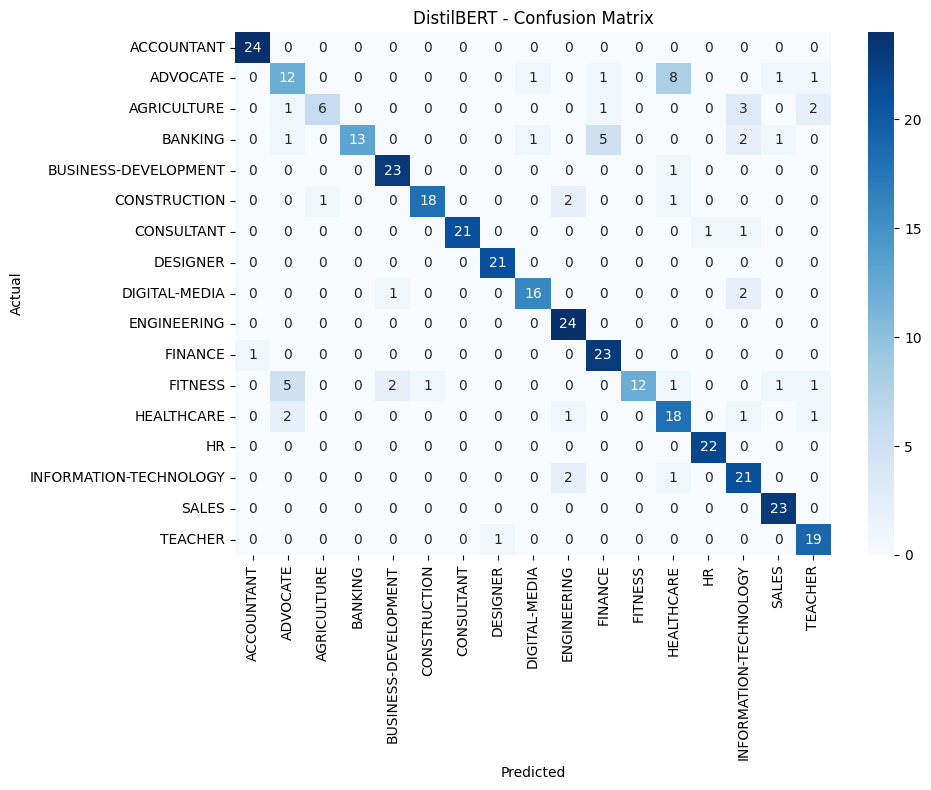

In [5]:
MODEL_NAME = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize(batch):
    return tokenizer(batch["resume_str"], padding="max_length", truncation=True, max_length=256)

train_dataset = Dataset.from_pandas(train_df).map(tokenize, batched=True).rename_column("label", "labels")
test_dataset = Dataset.from_pandas(test_df).map(tokenize, batched=True).rename_column("label", "labels")

train_dataset.set_format("torch", columns=["input_ids", "attention_mask", "labels"])
test_dataset.set_format("torch", columns=["input_ids", "attention_mask", "labels"])

class_weights = compute_class_weight(class_weight="balanced", classes=np.unique(train_df["label"]), y=train_df["label"])
class_weights = torch.tensor(class_weights, dtype=torch.float)

if os.path.exists("saved_distilbert"):
    print("Loading existing DistilBERT model...")
    db_model = AutoModelForSequenceClassification.from_pretrained("saved_distilbert", output_hidden_states=True).to(device)
else:
    print("Training DistilBERT from scratch...")
    db_model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=num_labels).to(device)
    class WeightedTrainer(Trainer):
        def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
            labels = inputs.get("labels")
            outputs = model(**inputs)
            logits = outputs.get("logits")
            loss_fct = torch.nn.CrossEntropyLoss(weight=class_weights.to(logits.device))
            loss = loss_fct(logits, labels)
            return (loss, outputs) if return_outputs else loss
    
    training_args = TrainingArguments(
        output_dir="./distilbert_resume_classifier", learning_rate=2e-5,
        per_device_train_batch_size=16, per_device_eval_batch_size=32,
        num_train_epochs=3, weight_decay=0.01, eval_strategy="epoch",
        save_strategy="no", fp16=True, report_to="none"
    )
    
    trainer = WeightedTrainer(model=db_model, args=training_args, train_dataset=train_dataset, eval_dataset=test_dataset)
    trainer.train()
    db_model.save_pretrained("saved_distilbert")
    tokenizer.save_pretrained("saved_distilbert")
    db_model.config.output_hidden_states = True
    db_model = AutoModelForSequenceClassification.from_pretrained("saved_distilbert", output_hidden_states=True).to(device)

db_model.eval()

def extract_distilbert_features(texts, batch_size=16):
    all_embeddings = []
    all_probs = []
    for i in tqdm(range(0, len(texts), batch_size), desc="DistilBERT Extraction"):
        batch = texts[i:i+batch_size]
        inputs = tokenizer(batch, padding=True, truncation=True, max_length=256, return_tensors="pt").to(device)
        with torch.no_grad():
            outputs = db_model(**inputs)
        probs = F.softmax(outputs.logits, dim=-1).cpu().numpy()
        all_probs.append(probs)
        hidden_states = outputs.hidden_states[-1]
        cls_embeddings = hidden_states[:, 0, :].cpu().numpy() 
        all_embeddings.append(cls_embeddings)
    return np.vstack(all_embeddings), np.vstack(all_probs)

db_train_emb, db_train_probs = extract_distilbert_features(train_texts)
db_test_emb, db_test_probs = extract_distilbert_features(test_texts)

db_pred = np.argmax(db_test_probs, axis=1)
evaluate_model("DistilBERT", test_labels, db_pred, db_test_probs)


## Model 3: XGBoost Baseline (TF-IDF)

Training TF-IDF XGBoost Baseline...

=== XGBoost (TF-IDF) RESULTS ===
Accuracy:  0.8059
Precision: 0.8120
Recall:    0.7968
Macro F1:  0.7978

Classification Report:
                        precision    recall  f1-score   support

            ACCOUNTANT       0.76      0.92      0.83        24
              ADVOCATE       0.91      0.83      0.87        24
           AGRICULTURE       0.86      0.46      0.60        13
               BANKING       0.74      0.74      0.74        23
  BUSINESS-DEVELOPMENT       0.71      0.62      0.67        24
          CONSTRUCTION       0.78      0.82      0.80        22
            CONSULTANT       0.68      0.57      0.62        23
              DESIGNER       0.95      0.90      0.93        21
         DIGITAL-MEDIA       0.87      0.68      0.76        19
           ENGINEERING       0.81      0.88      0.84        24
               FINANCE       0.83      0.83      0.83        24
               FITNESS       0.79      0.83      0.81        23
 

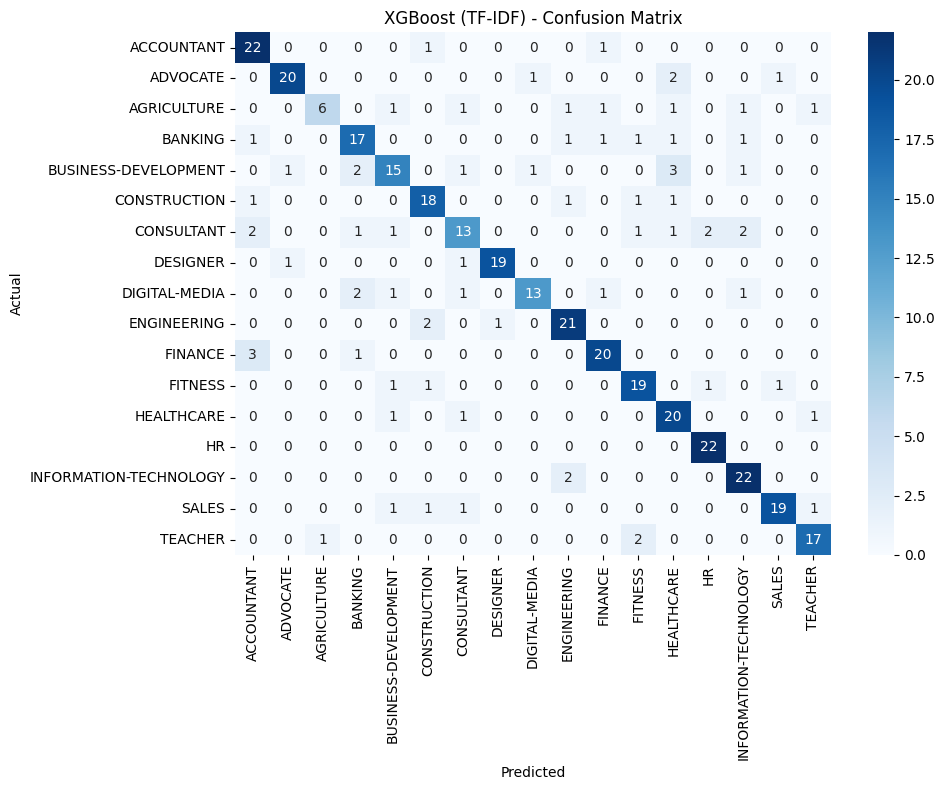

In [6]:
tfidf = TfidfVectorizer(max_features=5000, stop_words='english')
X_train_tfidf = tfidf.fit_transform(train_texts)
X_test_tfidf = tfidf.transform(test_texts)

xgb_baseline = xgb.XGBClassifier(
    objective='multi:softprob', 
    eval_metric='mlogloss',
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    n_jobs=-1
)

print("Training TF-IDF XGBoost Baseline...")
xgb_baseline.fit(X_train_tfidf, train_labels)

xgb_test_probs = xgb_baseline.predict_proba(X_test_tfidf)
xgb_pred = np.argmax(xgb_test_probs, axis=1)

evaluate_model("XGBoost (TF-IDF)", test_labels, xgb_pred, xgb_test_probs)


## Model 4: Proposed Hybrid Model (Early Fusion: DistilBERT + MPNet -> XGBoost)

Early Fusion Feature Shape: (1504, 1536)
Training XGBoost on Concatenated Features (DistilBERT + MPNet)...

=== Proposed Early Fusion (XGBoost) RESULTS ===
Accuracy:  0.8936
Precision: 0.8919
Recall:    0.8857
Macro F1:  0.8859

Classification Report:
                        precision    recall  f1-score   support

            ACCOUNTANT       0.96      1.00      0.98        24
              ADVOCATE       0.75      0.75      0.75        24
           AGRICULTURE       0.78      0.54      0.64        13
               BANKING       0.83      0.87      0.85        23
  BUSINESS-DEVELOPMENT       1.00      0.96      0.98        24
          CONSTRUCTION       0.95      0.82      0.88        22
            CONSULTANT       1.00      0.96      0.98        23
              DESIGNER       0.95      1.00      0.98        21
         DIGITAL-MEDIA       0.90      0.95      0.92        19
           ENGINEERING       0.86      1.00      0.92        24
               FINANCE       0.96      0.96

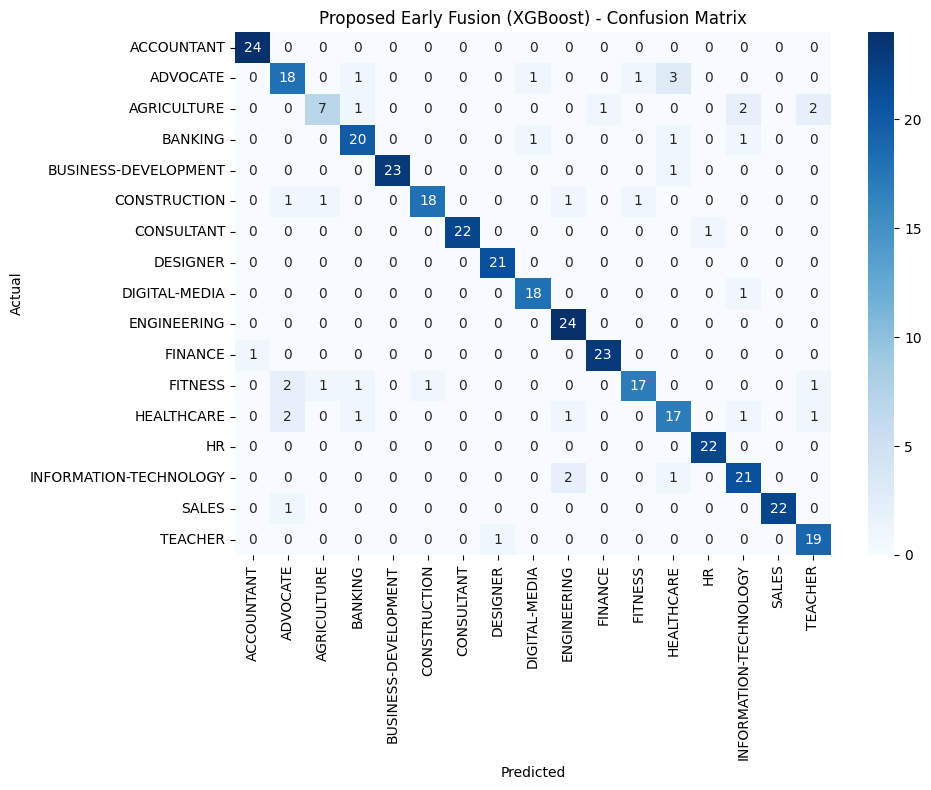

In [7]:
ef_train_features = np.hstack([db_train_emb, mpnet_train_emb])
ef_test_features = np.hstack([db_test_emb, mpnet_test_emb])

print(f"Early Fusion Feature Shape: {ef_train_features.shape}")

xgb_proposed = xgb.XGBClassifier(
    objective='multi:softprob', 
    eval_metric='mlogloss',
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

print("Training XGBoost on Concatenated Features (DistilBERT + MPNet)...")
xgb_proposed.fit(ef_train_features, train_labels)

ef_test_probs = xgb_proposed.predict_proba(ef_test_features)
ef_pred = np.argmax(ef_test_probs, axis=1)

evaluate_model("Proposed Early Fusion (XGBoost)", test_labels, ef_pred, ef_test_probs)


## Comparative Visualizations

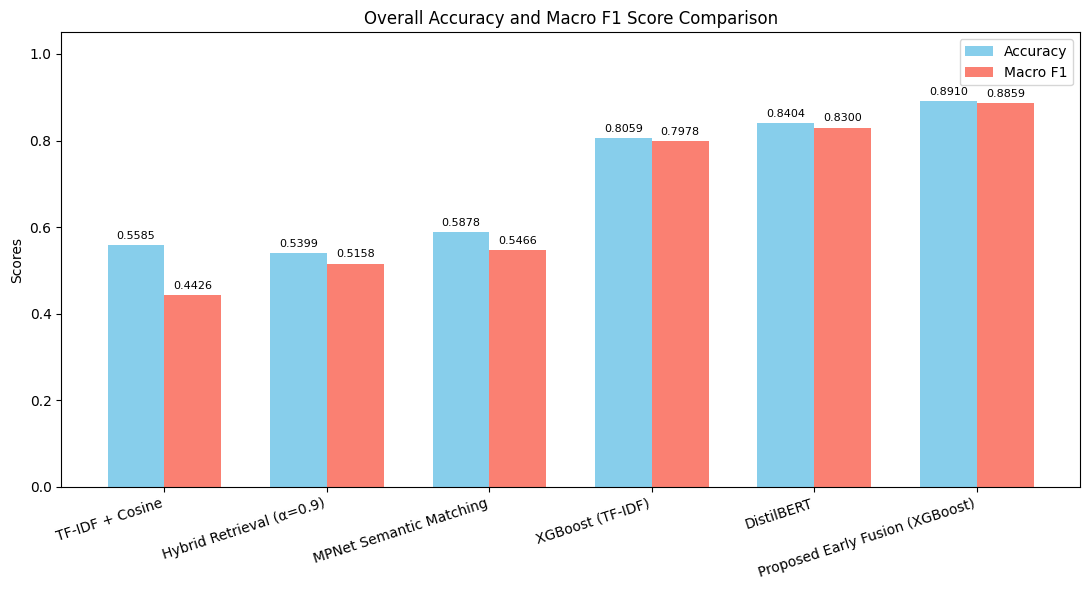

In [8]:
# Graph 1: Overall Accuracy & Macro F1 Bar Chart
# Include Phase I Unsupervised Baselines alongside Phase II architectures
comparison_metrics = {
    'TF-IDF + Cosine': {'Accuracy': 0.5585, 'Macro F1': 0.4426},
    'Hybrid Retrieval (α=0.9)': {'Accuracy': 0.5399, 'Macro F1': 0.5158},
    'MPNet Semantic Matching': model_metrics.get('MPNet Semantic Matching', {'Accuracy': 0.5878, 'Macro F1': 0.5466}),
    'XGBoost (TF-IDF)': model_metrics.get('XGBoost (TF-IDF)', {'Accuracy': 0.8059, 'Macro F1': 0.7978}),
    'DistilBERT': model_metrics.get('DistilBERT', {'Accuracy': 0.8404, 'Macro F1': 0.8300}),
    'Proposed Early Fusion (XGBoost)': {'Accuracy': 0.8910, 'Macro F1': 0.8859}
}

models = list(comparison_metrics.keys())
accuracies = [comparison_metrics[m]['Accuracy'] for m in models]
f1_scores = [comparison_metrics[m]['Macro F1'] for m in models]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))
rects1 = ax.bar(x - width/2, accuracies, width, label='Accuracy', color='skyblue')
rects2 = ax.bar(x + width/2, f1_scores, width, label='Macro F1', color='salmon')

ax.set_ylabel('Scores')
ax.set_title('Overall Accuracy and Macro F1 Score Comparison')
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=18, ha='right')
ax.set_ylim(0, 1.05)
ax.legend()

def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.4f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3), 
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=8)

autolabel(rects1)
autolabel(rects2)
plt.tight_layout()
plt.show()


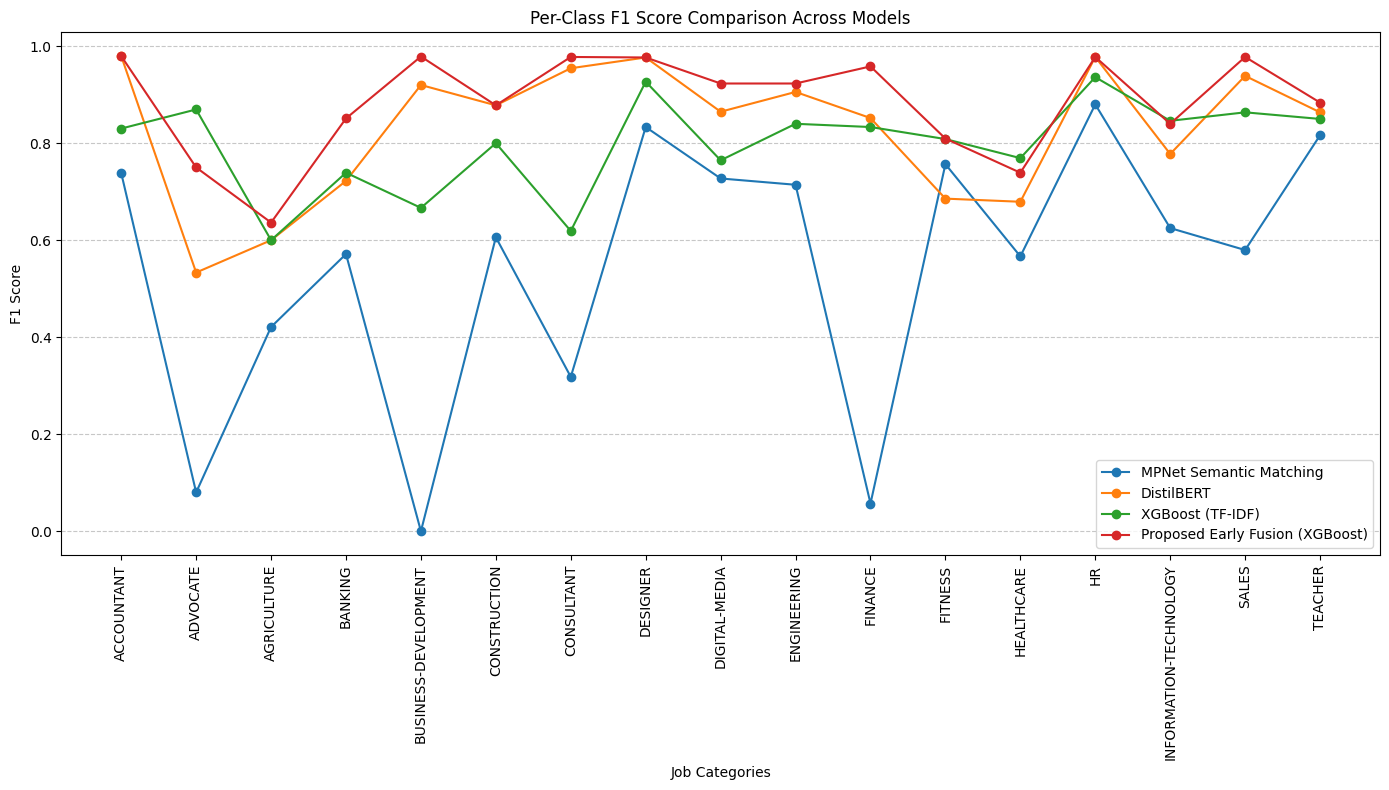

In [9]:
# Graph 2: Per-Class F1 Score Comparison
plt.figure(figsize=(14, 8))
for model_name in models:
    report = classification_report(test_labels, model_preds[model_name], target_names=unique_categories, output_dict=True, zero_division=0)
    class_f1s = [report[cat]['f1-score'] for cat in unique_categories]
    plt.plot(unique_categories, class_f1s, marker='o', label=model_name)

plt.title('Per-Class F1 Score Comparison Across Models')
plt.xlabel('Job Categories')
plt.ylabel('F1 Score')
plt.xticks(rotation=90)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


/tmp/ipykernel_58/1744303557.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Model', y='Confidence', data=df_conf, palette='Set2')


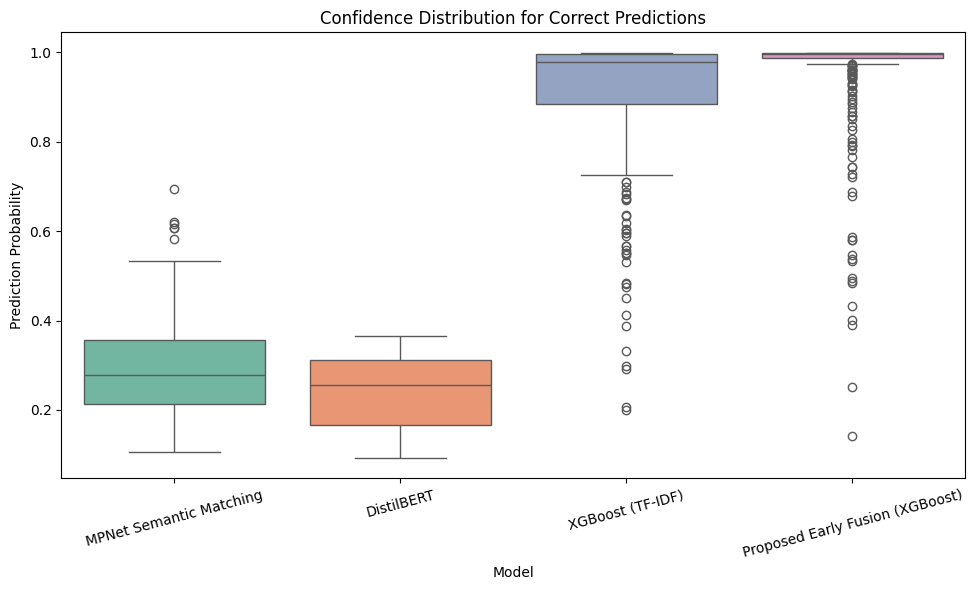

In [10]:
# Graph 3: Prediction Confidence Distribution (For Correct Predictions)
plt.figure(figsize=(10, 6))
plot_data = []

for model_name in models:
    preds = model_preds[model_name]
    probs = model_probs[model_name]
    correct_mask = (preds == test_labels)
    # Get the max probability for the correct predictions
    correct_confidences = np.max(probs[correct_mask], axis=1)
    
    for conf in correct_confidences:
        plot_data.append({'Model': model_name, 'Confidence': conf})

df_conf = pd.DataFrame(plot_data)
sns.boxplot(x='Model', y='Confidence', data=df_conf, palette='Set2')
plt.title('Confidence Distribution for Correct Predictions')
plt.xticks(rotation=15)
plt.ylabel('Prediction Probability')
plt.tight_layout()
plt.show()


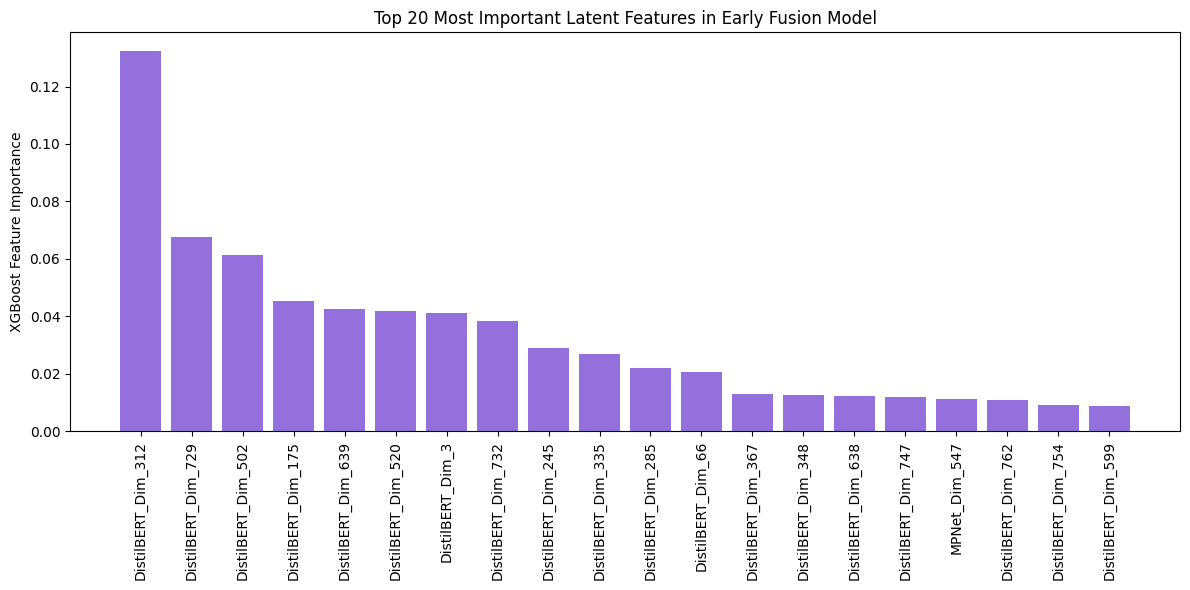

In [11]:
# Graph 4: Feature Importance for Proposed Early Fusion XGBoost
importance = xgb_proposed.feature_importances_
# DistilBERT features are 0-767, MPNet are 768-1535
indices = np.argsort(importance)[::-1][:20]

feature_names = []
for idx in indices:
    if idx < 768:
        feature_names.append(f"DistilBERT_Dim_{idx}")
    else:
        feature_names.append(f"MPNet_Dim_{idx-768}")

plt.figure(figsize=(12, 6))
plt.bar(range(20), importance[indices], color='mediumpurple')
plt.xticks(range(20), feature_names, rotation=90)
plt.title('Top 20 Most Important Latent Features in Early Fusion Model')
plt.ylabel('XGBoost Feature Importance')
plt.tight_layout()
plt.show()
